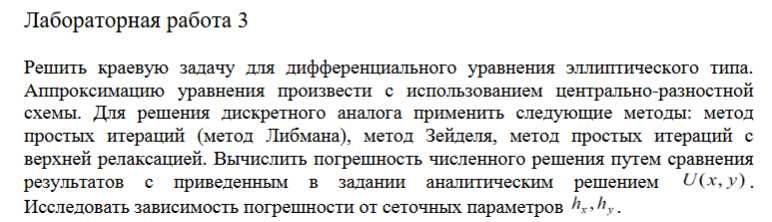

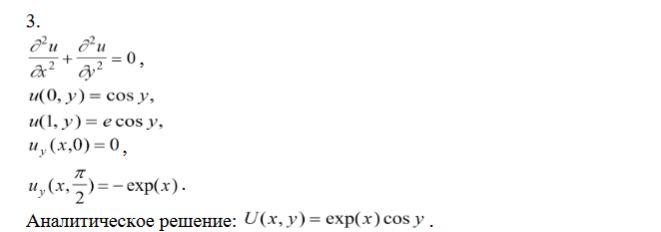

## Конечно-разностная схема

Введём равномерную сетку

$$x_i=ih_x,\quad i=0,1,\ldots,N_x,\qquad y_j=jh_y,\quad j=0,1,\ldots,N_y.$$

Во внутренних узлах используем центрально-разностную аппроксимацию второго порядка:

$$\frac{u_{i-1,j}-2u_{i,j}+u_{i+1,j}}{h_x^2}+\frac{u_{i,j-1}-2u_{i,j}+u_{i,j+1}}{h_y^2}=0.$$

Отсюда значение, вычисляемое на одной итерации, равно

$$u_{i,j}^{*}=\frac{h_y^2(u_{i-1,j}+u_{i+1,j})+h_x^2(u_{i,j-1}+u_{i,j+1})}{2(h_x^2+h_y^2)}.$$

Условия Дирихле задаются точно. Условия Неймана аппроксимируются односторонними формулами второго порядка:

$$u_{i,0}=\frac{4u_{i,1}-u_{i,2}}{3},\qquad u_{i,N_y}=\frac{4u_{i,N_y-1}-u_{i,N_y-2}-2h_y e^{x_i}}{3}.$$

Граничные значения исключаются из уравнений для строк $j=1$ и $j=N_y-1$. Это сохраняет второй порядок аппроксимации и даёт устойчивые расчётные формулы для итерационных методов.

In [142]:
from math import cos, exp, log, pi
import matplotlib.pyplot as plt
import numpy as np

# Расчётная область и основная сетка.
x0 = 0.0
xk = 1.0
y0 = 0.0
yk = pi/2
N_x = 20
N_y = 20
epsilon = 1e-9
omega = 1.5

def phi_left(y):
    return cos(y)

def phi_right(y):
    return exp(1)*cos(y)

def exact_solution(x, y):
    return exp(x)*cos(y)

def make_grid(number_of_intervals, left, right):
    step = (right - left)/number_of_intervals
    grid = [left + i*step for i in range(number_of_intervals + 1)]
    return grid, step

## Итерационные методы

В методе Либмана все значения $u^*$ вычисляются по предыдущему приближению. Метод Зейделя сразу использует уже обновлённые узлы. Для верхней релаксации применяется формула

$$u_{i,j}^{k+1}=(1-\omega)u_{i,j}^{k}+\omega u_{i,j}^{*},\qquad 1<\omega<2.$$

В расчёте принято $\omega=1.7$. Итерации завершаются при выполнении условия

$$\max_{i,j}|u_{i,j}^{k+1}-u_{i,j}^{k}|<\varepsilon.$$

In [143]:
def initial_approximation(x_grid, y_grid):
    # Линейная интерполяция между условиями на x = 0 и x = 1.
    N_x_local = len(x_grid) - 1
    N_y_local = len(y_grid) - 1
    u = [[0.0]*(N_y_local + 1) for _ in range(N_x_local + 1)]

    for i, x in enumerate(x_grid):
        for j, y in enumerate(y_grid):
            u[i][j] = (1 - x)*phi_left(y) + x*phi_right(y)

    return u

def apply_neumann_boundaries(u, x_grid, h_y):
    N_x_local = len(x_grid) - 1
    N_y_local = len(u[0]) - 1

    for i in range(1, N_x_local):
        u[i][0] = (4*u[i][1] - u[i][2])/3
        u[i][N_y_local] = (
            4*u[i][N_y_local - 1]
            - u[i][N_y_local - 2]
            - 2*h_y*exp(x_grid[i])
        )/3

def simple_iteration_value(u, i, j, x_grid, h_x, h_y):
    N_y_local = len(u[0]) - 1
    h_x_squared = h_x**2
    h_y_squared = h_y**2

    # В этих двух строках граничные значения уже исключены.
    if j == 1:
        return (
            h_y_squared*(u[i - 1][j] + u[i + 1][j])
            + 2*h_x_squared*u[i][j + 1]/3
        )/(2*h_y_squared + 2*h_x_squared/3)

    if j == N_y_local - 1:
        return (
            h_y_squared*(u[i - 1][j] + u[i + 1][j])
            + 2*h_x_squared*u[i][j - 1]/3
            - 2*h_x_squared*h_y*exp(x_grid[i])/3
        )/(2*h_y_squared + 2*h_x_squared/3)

    return (
        h_y_squared*(u[i - 1][j] + u[i + 1][j])
        + h_x_squared*(u[i][j - 1] + u[i][j + 1])
    )/(2*(h_x_squared + h_y_squared))

In [144]:
def solve(N_x_local, N_y_local, method, tolerance=epsilon,
          relaxation_parameter=omega, max_iterations=100000):
    x_grid, h_x = make_grid(N_x_local, x0, xk)
    y_grid, h_y = make_grid(N_y_local, y0, yk)
    u = initial_approximation(x_grid, y_grid)
    apply_neumann_boundaries(u, x_grid, h_y)
    change_history = []

    for iteration in range(1, max_iterations + 1):
        previous = [row.copy() for row in u]

        if method == 'liebmann':
            for i in range(1, N_x_local):
                for j in range(1, N_y_local):
                    u[i][j] = simple_iteration_value(
                        previous, i, j, x_grid, h_x, h_y
                    )

        if method == 'seidel':
            for i in range(1, N_x_local):
                for j in range(1, N_y_local):
                    u[i][j] = simple_iteration_value(
                        u, i, j, x_grid, h_x, h_y
                    )


            
        
        else:
            current_omega = 1.0 if method == 'seidel' else relaxation_parameter
            for i in range(1, N_x_local):
                for j in range(1, N_y_local):
                    simple_value = simple_iteration_value(
                        u, i, j, x_grid, h_x, h_y
                    )
                    u[i][j] = (
                        (1 - current_omega)*u[i][j]
                        + current_omega*simple_value
                    )

        apply_neumann_boundaries(u, x_grid, h_y)
        max_change = max(
            abs(u[i][j] - previous[i][j])
            for i in range(N_x_local + 1)
            for j in range(N_y_local + 1)
        )
        change_history.append(max_change)

        if max_change < tolerance:
            return x_grid, y_grid, u, iteration, change_history

    raise RuntimeError('Итерационный метод не сошёлся')

def error_norms(u, x_grid, y_grid):
    errors = [
        abs(u[i][j] - exact_solution(x_grid[i], y_grid[j]))
        for i in range(len(x_grid))
        for j in range(len(y_grid))
    ]
    max_norm = max(errors)
    rms_norm = (sum(error**2 for error in errors)/len(errors))**0.5
    return max_norm, rms_norm

## Сравнение методов

Все три метода решают одну и ту же разностную задачу, поэтому после сходимости их погрешности должны практически совпадать. Основное различие состоит в числе итераций.

In [145]:
methods = {
    'Метод Либмана': 'liebmann',
    'Метод Зейделя': 'seidel',
    'Верхняя релаксация': 'sor',
}

results = {}
print(f'h_x = {(xk - x0)/N_x:.5f}, h_y = {(yk - y0)/N_y:.5f}, epsilon = {epsilon:.0e}')
print(f'{"Метод":22} {"Итерации":>10} {"||du||_inf":>14} {"||e||_inf":>14} {"||e||_rms":>14}')

for method_name, method in methods.items():
    result = solve(N_x, N_y, method)
    x_grid, y_grid, u, iterations, change_history = result
    max_norm, rms_norm = error_norms(u, x_grid, y_grid)
    results[method_name] = {
        'u': u,
        'iterations': iterations,
        'history': change_history,
        'max_norm': max_norm,
        'rms_norm': rms_norm,
    }
    print(
        f'{method_name:22} {iterations:10d} {change_history[-1]:14.6e} '
        f'{max_norm:14.6e} {rms_norm:14.6e}'
    )

h_x = 0.05000, h_y = 0.07854, epsilon = 1e-09
Метод                    Итерации     ||du||_inf      ||e||_inf      ||e||_rms
Метод Либмана                 253   9.941452e-10   1.377338e-03   3.784977e-04
Метод Зейделя                 817   9.936727e-10   1.377372e-03   3.785164e-04
Верхняя релаксация            286   9.725079e-10   1.377338e-03   3.784980e-04


## Численное и аналитическое решения

На графиках показаны линии уровня решения на основной сетке.

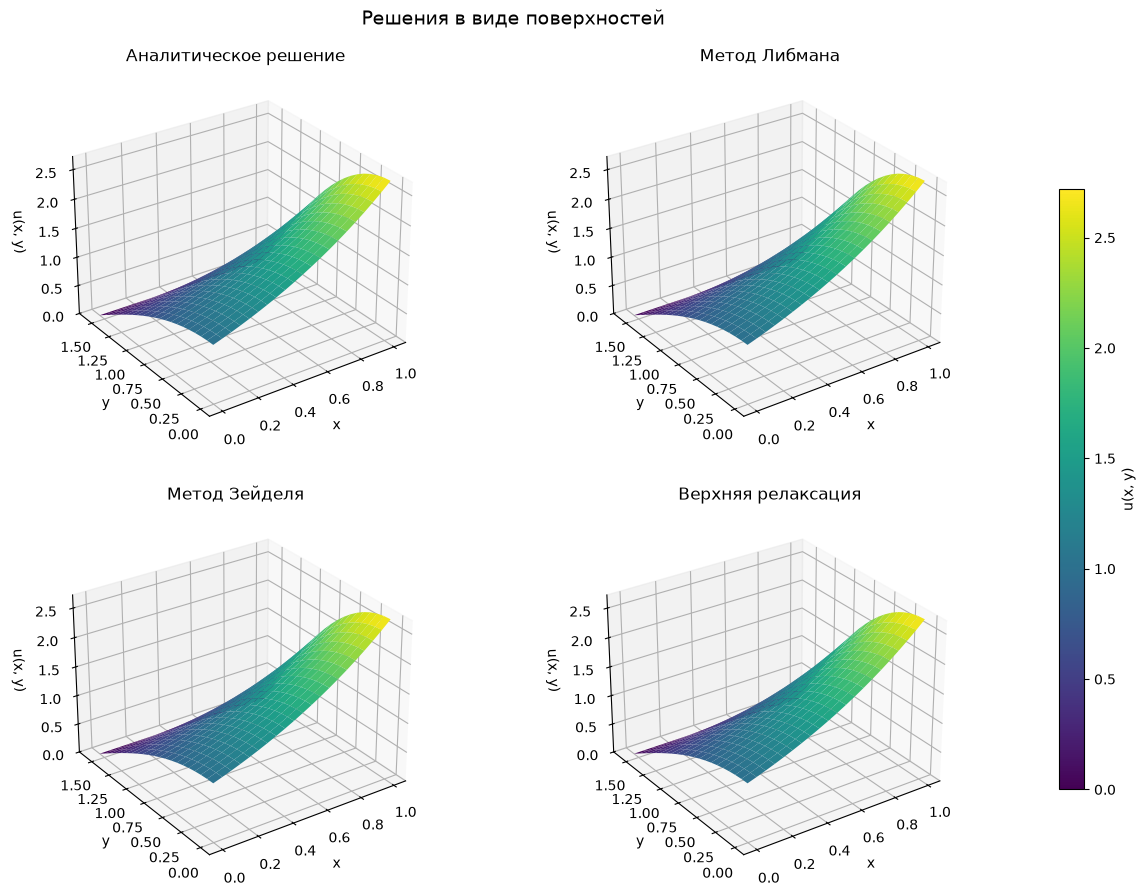

In [146]:
exact_grid = [
    [exact_solution(x_grid[i], y_grid[j]) for i in range(N_x + 1)]
    for j in range(N_y + 1)
]

plot_data = [('Аналитическое решение', exact_grid)]
for method_name in methods:
    u = results[method_name]['u']
    # contourf ожидает строки, соответствующие значениям y.
    transposed_u = [[u[i][j] for i in range(N_x + 1)]
                    for j in range(N_y + 1)]
    plot_data.append((method_name, transposed_u))

X, Y = np.meshgrid(x_grid, y_grid)
z_min = min(min(row) for _, values in plot_data for row in values)
z_max = max(max(row) for _, values in plot_data for row in values)

figure = plt.figure(figsize=(14, 10))
for plot_number, (title, values) in enumerate(plot_data, start=1):
    axis = figure.add_subplot(2, 2, plot_number, projection='3d')
    surface = axis.plot_surface(
        X, Y, np.array(values), cmap='viridis',
        vmin=z_min, vmax=z_max, edgecolor='none'
    )
    axis.set_title(title)
    axis.set_xlabel('x')
    axis.set_ylabel('y')
    axis.set_zlabel('u(x, y)')
    axis.set_zlim(z_min, z_max)
    axis.view_init(elev=28, azim=-125)

figure.suptitle('Решения в виде поверхностей', fontsize=14)
figure.subplots_adjust(top=0.92, right=0.86, hspace=0.18, wspace=0.08)
color_axis = figure.add_axes([0.89, 0.20, 0.018, 0.60])
figure.colorbar(surface, cax=color_axis, label='u(x, y)')
plt.show()

## Сходимость итераций

На графике приведена величина $\|u^{k+1}-u^k\|_\infty$. Метод верхней релаксации достигает заданной точности заметно быстрее.

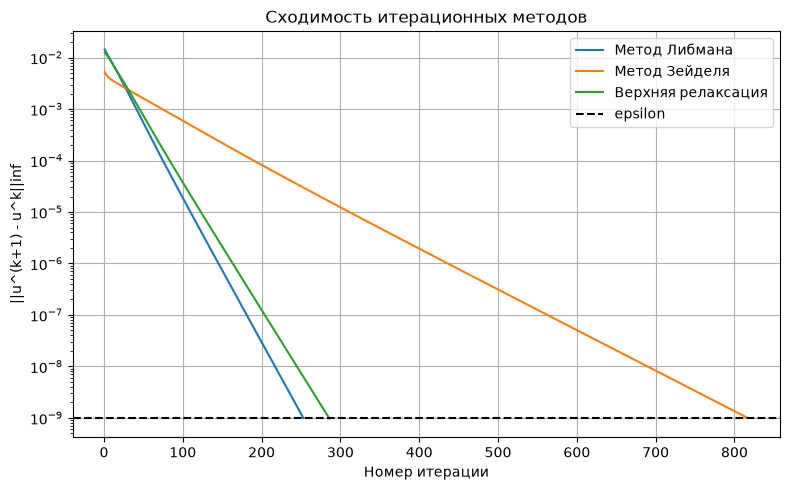

In [147]:
figure, axis = plt.subplots(figsize=(8, 5))

for method_name, result in results.items():
    iteration_numbers = range(1, result['iterations'] + 1)
    axis.semilogy(iteration_numbers, result['history'], label=method_name)

axis.axhline(epsilon, color='black', linestyle='--', label='epsilon')
axis.set_title('Сходимость итерационных методов')
axis.set_xlabel('Номер итерации')
axis.set_ylabel('||u^(k+1) - u^k||inf')
axis.grid(True)
axis.legend()
figure.tight_layout()
plt.show()

## Зависимость погрешности от параметров сетки

Для исследования сеточной погрешности используется метод верхней релаксации с более строгим критерием остановки $\varepsilon=10^{-10}$. Отдельно уменьшаются $h_x$ при фиксированном $h_y$, $h_y$ при фиксированном $h_x$, а затем оба шага одновременно.

In [148]:
grid_sizes = [
    (10, 10), (20, 20), (40, 40),
    (10, 40), (20, 40),
    (40, 10), (40, 20),
]
grid_study = {}

print(f'{"N_x":>5} {"N_y":>5} {"h_x":>10} {"h_y":>10} {"Итерации":>10} {"||e||_inf":>14}')
for N_x_local, N_y_local in grid_sizes:
    result = solve(N_x_local, N_y_local, 'sor', tolerance=1e-10)
    x_grid_local, y_grid_local, u, iterations, _ = result
    max_norm, _ = error_norms(u, x_grid_local, y_grid_local)
    h_x = (xk - x0)/N_x_local
    h_y = (yk - y0)/N_y_local
    grid_study[(N_x_local, N_y_local)] = (h_x, h_y, max_norm)
    print(
        f'{N_x_local:5d} {N_y_local:5d} {h_x:10.5f} {h_y:10.5f} '
        f'{iterations:10d} {max_norm:14.6e}'
    )

proportional_errors = [grid_study[(N, N)][2] for N in (10, 20, 40)]
orders = [
    log(proportional_errors[i - 1]/proportional_errors[i])/log(2)
    for i in range(1, len(proportional_errors))
]
print(f'\nПорядок при одновременном сгущении: {orders[0]:.3f}, {orders[1]:.3f}')

  N_x   N_y        h_x        h_y   Итерации      ||e||_inf
   10    10    0.10000    0.15708         75   5.665406e-03
   20    20    0.05000    0.07854        327   1.377331e-03
   40    40    0.02500    0.03927       1249   3.417204e-04
   10    40    0.10000    0.03927        430   3.883796e-04
   20    40    0.05000    0.03927        597   3.510289e-04
   40    10    0.02500    0.15708        932   5.635781e-03
   40    20    0.02500    0.07854        995   1.368428e-03

Порядок при одновременном сгущении: 2.040, 2.011


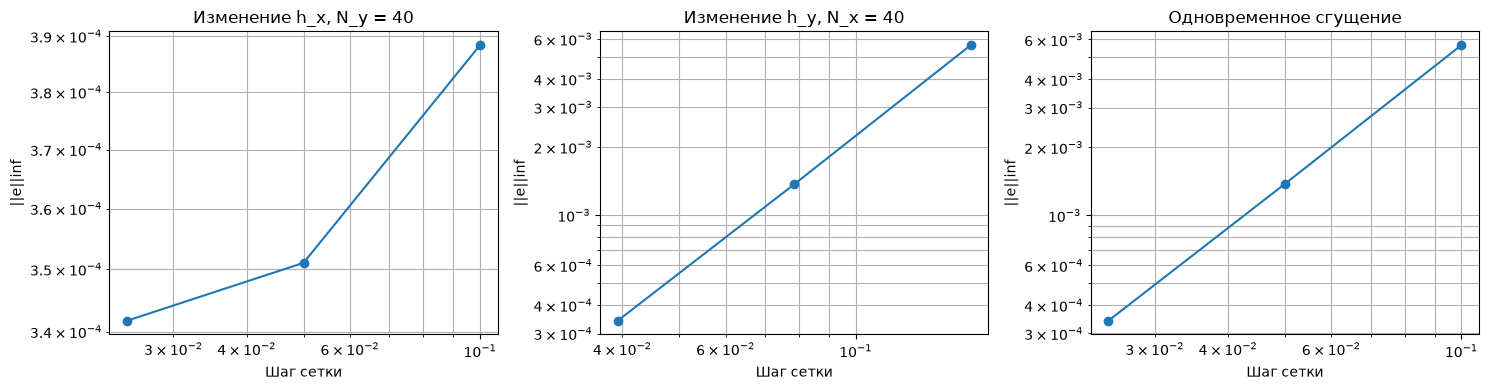

In [149]:
studies = [
    ('Изменение h_x, N_y = 40', [(10, 40), (20, 40), (40, 40)], 0),
    ('Изменение h_y, N_x = 40', [(40, 10), (40, 20), (40, 40)], 1),
    ('Одновременное сгущение', [(10, 10), (20, 20), (40, 40)], 0),
]

figure = plt.figure(figsize=(15, 4))
for plot_number, (title, sizes, step_number) in enumerate(studies, start=1):
    axis = figure.add_subplot(1, 3, plot_number)
    steps = [grid_study[size][step_number] for size in sizes]
    errors = [grid_study[size][2] for size in sizes]
    axis.loglog(steps, errors, 'o-')
    axis.set_title(title)
    axis.set_xlabel('Шаг сетки')
    axis.set_ylabel('||e||inf')
    axis.grid(True, which='both')

figure.tight_layout()
plt.show()

### Вывод

Методы Либмана, Зейделя и верхней релаксации сходятся к одному решению разностной задачи. Верхняя релаксация требует наименьшего числа итераций. При одновременном уменьшении $h_x$ и $h_y$ максимальная погрешность убывает примерно в четыре раза, что подтверждает второй порядок конечно-разностной аппроксимации.